# Q3: Abstractive Summarization with a Transformer Encoder-Decoder (from scratch)
**Dataset:** CNN / Daily Mail 3.0.0 | **Tokenizer:** pre-trained `bert-base-uncased` WordPiece (allowed) | **Model:** hand-written Transformer (no nn.Transformer / nn.MultiheadAttention / SDPA / HF model classes / pre-trained weights)

Notebook map:
1. Setup & configuration
2. Data loading
3. Tokenizer, truncation statistics, preprocessing
4. Datasets / DataLoaders (padding)
5. Transformer components from scratch (attention, FFN, positional encoding, layers, masks, model)
6. Sanity tests (causal mask, padding mask)
7. Training (Adam + Noam schedule, teacher forcing, early stopping, best-checkpoint restore)
8. Loss curves
9. Greedy decoding (encoder run once) + ROUGE on the FULL test set (+ Lead-3 reference check)
10. Qualitative analysis incl. failure cases
11. Encoder-decoder attention heatmap
12. Report facts

In [ ]:
%pip install -q datasets transformers rouge_score nltk matplotlib pandas tqdm

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


In [ ]:
# 1. Imports, seeds, device
import os, math, time, random, json, re
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
import matplotlib.pyplot as plt
from tqdm.auto import tqdm
from datasets import load_dataset
from transformers import AutoTokenizer
from rouge_score import rouge_scorer
import nltk

SEED = 42
def set_seed(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)
set_seed(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
USE_AMP = device.type == "cuda"          # mixed precision for speed on GPU
print("device:", device, "| AMP:", USE_AMP)

device: cuda | AMP: True


In [ ]:
TOKENIZER_NAME = "bert-base-uncased"
MAX_SRC_LEN, MAX_TGT_LEN = 400, 128

TRAIN_SIZE = 60_000          # use 100_000 if you have time; 60k ≈ 8 min/epoch on your GPU
VAL_SIZE   = None            # full 13,368
TEST_SIZE  = None            # full 11,490  <- required for the report

BATCH_SIZE   = 32
WARMUP_STEPS = 2000
LR_FACTOR    = 0.5           # peak lr ≈ 7e-4  (set ONCE, nowhere else)
EPOCHS, PATIENCE = 12, 3
USE_AMP = False

D_MODEL, N_HEADS, N_LAYERS, D_FF, DROPOUT = 256, 4, 3, 1024, 0.1
TIE_EMBEDDINGS = True
LABEL_SMOOTH = 0.0
CLIP_NORM = 1.0
CKPT_PATH = "/content/best_transformer.pt"
DECODE_BATCH = 64

## 2. Load the dataset

In [ ]:
try:
    ds = load_dataset("cnn_dailymail", "3.0.0")            # columns: article, highlights, id
except Exception as e:
    print("Falling back to hub mirror because:", repr(e)[:150])
    ds = load_dataset("abisee/cnn_dailymail", "3.0.0")
print(ds)
print("Train / Val / Test sizes:", len(ds["train"]), len(ds["validation"]), len(ds["test"]))
print("\nSAMPLE highlights (note the \\n between sentences):")
print(repr(ds["train"][0]["highlights"]))

README.md:   0%|          | 0.00/15.6k [00:00<?, ?B/s]

Falling back to hub mirror because: HfUriError("Invalid HF URI 'hf://datasets/cnn_dailymail@96df5e686bee6baa90b8bee7c28b81fa3fa6223d/.huggingface.yaml'. Repository id must be 'namespace/


README.md:   0%|          | 0.00/15.6k [00:00<?, ?B/s]

3.0.0/train-00000-of-00003.parquet: reconstructing file:   0%|          |  0.00B /  257MB            

3.0.0/train-00000-of-00003.parquet: downloading bytes:           |  0.00B            

3.0.0/train-00001-of-00003.parquet: reconstructing file:   0%|          |  0.00B /  257MB            

... (7 outputs left out)

Generating train split:   0%|          | 0/287113 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/13368 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/11490 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['article', 'highlights', 'id'],
        num_rows: 287113
    })
    validation: Dataset({
        features: ['article', 'highlights', 'id'],
        num_rows: 13368
    })
    test: Dataset({
        features: ['article', 'highlights', 'id'],
        num_rows: 11490
    })
})
Train / Val / Test sizes: 287113 13368 11490

SAMPLE highlights (note the \n between sentences):
"Harry Potter star Daniel Radcliffe gets £20M fortune as he turns 18 Monday .\nYoung actor says he has no plans to fritter his cash away .\nRadcliffe's earnings from first five Potter films have been held in trust fund ."


## 3. Tokenizer & preprocessing
* One **shared** WordPiece vocabulary for articles and summaries (bert-base-uncased, 30,522 tokens).
* `[PAD]`=pad, `[CLS]`=**start** token, `[SEP]`=**end** token.
* Summary sentence boundaries (`\n`) are **kept** as the special token `[unused1]` (called NL below) so
  that generated summaries can be split into sentences again for **ROUGE-Lsum**.
* Decoder input = `[start] + summary` (shifted right); target = `summary + [end]` (shifted left).
> **Memory note:** First run the notebook with the small debug sizes in the configuration cell. After the full pipeline works, increase the training subset and restore article/summary lengths for your final experiment.


In [ ]:
tok = AutoTokenizer.from_pretrained(TOKENIZER_NAME)
PAD_ID, START_ID, END_ID = tok.pad_token_id, tok.cls_token_id, tok.sep_token_id
NL_ID = tok.convert_tokens_to_ids("[unused1]")           # newline marker inside summaries
VOCAB_SIZE = len(tok)
print(f"vocab={VOCAB_SIZE} PAD={PAD_ID} START={START_ID} END={END_ID} NL={NL_ID}")
print(tok.tokenize("Harry Potter star Daniel Radcliffe gets 20M fortune"))   # lowercased wordpieces

config.json:   0%|          | 0.00/570 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

vocab=30522 PAD=0 START=101 END=102 NL=2
['harry', 'potter', 'star', 'daniel', 'radcliffe', 'gets', '20', '##m', 'fortune']


In [ ]:
def clean(text):
    """Light cleaning: collapse whitespace. Lowercasing is done by the uncased tokenizer."""
    return re.sub(r"\s+", " ", text).strip()

def encode_articles(texts, chunk=5000):
    out = []
    for i in tqdm(range(0, len(texts), chunk), desc="tokenize articles"):
        enc = tok([clean(t) for t in texts[i:i+chunk]], add_special_tokens=False,
                  truncation=True, max_length=MAX_SRC_LEN)
        out.extend(enc["input_ids"])
    return out


def encode_summaries(texts, chunk=500):
    """Tokenize summaries in chunks and preserve sentence boundaries."""
    out = []

    for start in tqdm(
        range(0, len(texts), chunk),
        desc="tokenize summaries"
    ):
        batch_texts = texts[start:start + chunk]

        flat = []
        owner = []

        for d, text in enumerate(batch_texts):
            for sentence in text.split("\n"):
                sentence = sentence.strip()
                if sentence:
                    flat.append(sentence)
                    owner.append(d)

        enc = tok(
            flat,
            add_special_tokens=False,
            truncation=True,
            max_length=MAX_TGT_LEN,
        )

        batch_out = [[] for _ in batch_texts]

        for d, ids in zip(owner, enc["input_ids"]):
            if batch_out[d]:
                batch_out[d].append(NL_ID)
            batch_out[d].extend(ids)

        out.extend([
            ids[:MAX_TGT_LEN - 1]
            for ids in batch_out
        ])

    return out


In [ ]:
# Truncation statistics, computed in chunks to avoid a large temporary tokenization object.
sample = ds["validation"].select(range(min(2000, len(ds["validation"]))))

def token_lengths_in_chunks(texts, chunk_size=100):
    lengths = []
    for start in tqdm(range(0, len(texts), chunk_size), desc="measure token lengths"):
        batch = texts[start:start + chunk_size]
        encoded = tok(batch, add_special_tokens=False, truncation=False)
        lengths.extend(len(ids) for ids in encoded["input_ids"])
        del encoded
    return lengths

a_texts = [clean(a) for a in sample["article"]]
s_texts = [h.replace("\n", " ") for h in sample["highlights"]]
a_len = token_lengths_in_chunks(a_texts)
s_len = token_lengths_in_chunks(s_texts)
for name, L, lim in [("article", a_len, MAX_SRC_LEN), ("summary", s_len, MAX_TGT_LEN - 1)]:
    L = np.array(L)
    print(f"{name:8s} median={np.median(L):.0f} p90={np.percentile(L,90):.0f} max={L.max()} "
          f"| longer than {lim}: {100*(L>lim).mean():.1f}%")

measure token lengths:   0%|          | 0/20 [00:00<?, ?it/s]

[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (964 > 512). Running this sequence through the model will result in indexing errors


measure token lengths:   0%|          | 0/20 [00:00<?, ?it/s]

article  median=680 p90=1379 max=2320 | longer than 400: 78.2%
summary  median=47 p90=73 max=187 | longer than 127: 0.4%


In [ ]:
def build_split(split, limit=None, shuffle=False, filter_empty=True, keep_raw=False, chunk_size=250):
    """Encode a dataset split incrementally, avoiding a full split of raw text in RAM."""
    d = ds[split]
    if shuffle:
        d = d.shuffle(seed=SEED)

    n = len(d) if limit is None else min(limit, len(d))
    all_src, all_tgt = [], []
    raw_articles, raw_highlights = [], []
    dropped = 0

    for start in tqdm(range(0, n, chunk_size), desc=f"prepare {split}"):
        end = min(start + chunk_size, n)
        batch = d[start:end]  # Only materialize this small slice as Python lists.
        arts, hls = batch["article"], batch["highlights"]
        src_batch = encode_articles(arts, chunk=chunk_size)
        tgt_batch = encode_summaries(hls, chunk=chunk_size)

        for article, highlight, src_ids, tgt_ids in zip(arts, hls, src_batch, tgt_batch):
            if filter_empty and (len(src_ids) == 0 or len(tgt_ids) == 0):
                dropped += 1
                continue
            all_src.append(src_ids)
            all_tgt.append(tgt_ids)
            if keep_raw:
                raw_articles.append(article)
                raw_highlights.append(highlight)

        # Release batch-local references before processing the next slice.
        del batch, arts, hls, src_batch, tgt_batch

    out = {"src": all_src, "tgt": all_tgt, "dropped": dropped}
    if keep_raw:
        out["article"] = raw_articles
        out["highlights"] = raw_highlights
    return out


# Start small. Increase TRAIN_SIZE after this pipeline completes reliably.
train = build_split("train", TRAIN_SIZE, shuffle=True, chunk_size=250)
val = build_split("validation", VAL_SIZE, chunk_size=250)
test = build_split("test", TEST_SIZE, filter_empty=False, keep_raw=True, chunk_size=100)

print(f"Train: {len(train['src'])} (dropped {train['dropped']})")
print(f"Validation: {len(val['src'])}")
print(f"Test: {len(test['src'])}")
print("Example summary:", tok.decode([t for t in train["tgt"][0] if t != NL_ID]))

prepare train:   0%|          | 0/240 [00:00<?, ?it/s]

tokenize articles:   0%|          | 0/1 [00:00<?, ?it/s]

tokenize summaries:   0%|          | 0/1 [00:00<?, ?it/s]

tokenize articles:   0%|          | 0/1 [00:00<?, ?it/s]

tokenize summaries:   0%|          | 0/1 [00:00<?, ?it/s]

tokenize articles:   0%|          | 0/1 [00:00<?, ?it/s]

... (812 outputs left out)

tokenize summaries:   0%|          | 0/1 [00:00<?, ?it/s]

tokenize articles:   0%|          | 0/1 [00:00<?, ?it/s]

tokenize summaries:   0%|          | 0/1 [00:00<?, ?it/s]

Train: 60000 (dropped 0)
Validation: 13368
Test: 11490
Example summary: john and. audrey cook were discovered alongside their daughter, maureen. they were found at tremarle home park in cornwall. investigators say the three died of carbon monoxide. poisoning.


## 4. Datasets and padded batches

In [ ]:
class SumDataset(Dataset):
    def __init__(self, src, tgt):
        self.src, self.tgt = src, tgt

    def __len__(self):
        return len(self.src)

    def __getitem__(self, i):
        return self.src[i], self.tgt[i]


def pad_batch(seqs, length=None, pad=PAD_ID):
    length = length or max(len(s) for s in seqs)
    out = torch.full((len(seqs), length), pad, dtype=torch.long)
    for i, s in enumerate(seqs):
        out[i, :len(s)] = torch.tensor(s, dtype=torch.long)
    return out


def collate(batch):
    srcs, tgts = zip(*batch)
    src = pad_batch(list(srcs))
    tgt_in = pad_batch([[START_ID] + t for t in tgts])
    tgt_out = pad_batch([t + [END_ID] for t in tgts])
    return src, tgt_in, tgt_out


# num_workers=0 avoids multiprocessing cleanup issues during Colab debugging.
train_loader = DataLoader(
    SumDataset(train["src"], train["tgt"]),
    batch_size=BATCH_SIZE,
    shuffle=True,
    collate_fn=collate,
    num_workers=0,
    pin_memory=(device.type == "cuda"),
)

val_loader = DataLoader(
    SumDataset(val["src"], val["tgt"]),
    batch_size=BATCH_SIZE,
    shuffle=False,
    collate_fn=collate,
    num_workers=0,
    pin_memory=(device.type == "cuda"),
)

s, ti, to = next(iter(train_loader))
print(s.shape, ti.shape, to.shape)
print("decoder input :", tok.convert_ids_to_tokens(ti[0][:12].tolist()))
print("decoder target:", tok.convert_ids_to_tokens(to[0][:12].tolist()))


torch.Size([32, 400]) torch.Size([32, 128]) torch.Size([32, 128])
decoder input : ['[CLS]', 'supreme', 'court', 'takes', 'on', 'a', 'challenge', 'to', '$', '123', ',', '200']
decoder target: ['supreme', 'court', 'takes', 'on', 'a', 'challenge', 'to', '$', '123', ',', '200', 'aggregate']


## 5. Transformer from scratch
Only `nn.Linear`, `nn.Embedding`, `nn.LayerNorm`, `nn.Dropout` and basic tensor ops are used.
Masks are boolean (`True` = may attend). Masked scores are filled with the dtype's minimum, which is
equivalent to adding `-inf` before the softmax in `softmax(QK^T/sqrt(d_k) + mask)V`.

In [ ]:
class MultiHeadAttention(nn.Module):
    """Attention(Q,K,V) = softmax(Q K^T / sqrt(d_k) + mask) V, with h parallel heads."""
    def __init__(self, d_model, n_heads, dropout):
        super().__init__()
        assert d_model % n_heads == 0
        self.h, self.dk = n_heads, d_model // n_heads
        self.w_q, self.w_k = nn.Linear(d_model, d_model), nn.Linear(d_model, d_model)
        self.w_v, self.w_o = nn.Linear(d_model, d_model), nn.Linear(d_model, d_model)
        self.drop = nn.Dropout(dropout)
        self.store_attn, self.attn = False, None      # lets us read attention weights for visualization

    def forward(self, q, k, v, mask=None):
        B, Tq, _ = q.shape
        Tk = k.shape[1]
        Q = self.w_q(q).view(B, Tq, self.h, self.dk).transpose(1, 2)   # (B,h,Tq,dk)
        K = self.w_k(k).view(B, Tk, self.h, self.dk).transpose(1, 2)   # (B,h,Tk,dk)
        V = self.w_v(v).view(B, Tk, self.h, self.dk).transpose(1, 2)
        scores = Q @ K.transpose(-2, -1) / math.sqrt(self.dk)          # (B,h,Tq,Tk)
        if mask is not None:                                           # mask broadcast to (B,1,Tq|1,Tk)
            scores = scores.masked_fill(~mask, torch.finfo(scores.dtype).min)
        attn = torch.softmax(scores, dim=-1)
        if self.store_attn:
            self.attn = attn.detach()
        out = self.drop(attn) @ V                                      # (B,h,Tq,dk)
        out = out.transpose(1, 2).contiguous().view(B, Tq, self.h * self.dk)
        return self.w_o(out)


class PositionwiseFFN(nn.Module):
    """FFN(x) = W2 * ReLU(W1 x + b1) + b2"""
    def __init__(self, d_model, d_ff, dropout):
        super().__init__()
        self.l1, self.l2, self.drop = nn.Linear(d_model, d_ff), nn.Linear(d_ff, d_model), nn.Dropout(dropout)
    def forward(self, x):
        return self.l2(self.drop(F.relu(self.l1(x))))


class PositionalEncoding(nn.Module):
    """PE(pos,2i)=sin(pos/10000^(2i/d)), PE(pos,2i+1)=cos(pos/10000^(2i/d))"""
    def __init__(self, d_model, max_len, dropout):
        super().__init__()
        pe = torch.zeros(max_len, d_model)
        pos = torch.arange(max_len).unsqueeze(1).float()
        div = torch.exp(torch.arange(0, d_model, 2).float() * (-math.log(10000.0) / d_model))  # 10000^(-2i/d)
        pe[:, 0::2], pe[:, 1::2] = torch.sin(pos * div), torch.cos(pos * div)
        self.register_buffer("pe", pe.unsqueeze(0))
        self.drop = nn.Dropout(dropout)
    def forward(self, x):
        return self.drop(x + self.pe[:, :x.size(1)])


class EncoderLayer(nn.Module):
    """Sub-layer wrapping: LayerNorm(x + Dropout(Sublayer(x)))"""
    def __init__(self, d_model, n_heads, d_ff, dropout):
        super().__init__()
        self.self_attn = MultiHeadAttention(d_model, n_heads, dropout)
        self.ffn = PositionwiseFFN(d_model, d_ff, dropout)
        self.n1, self.n2, self.drop = nn.LayerNorm(d_model), nn.LayerNorm(d_model), nn.Dropout(dropout)
    def forward(self, x, src_mask):
        x = self.n1(x + self.drop(self.self_attn(x, x, x, src_mask)))
        return self.n2(x + self.drop(self.ffn(x)))


class DecoderLayer(nn.Module):
    def __init__(self, d_model, n_heads, d_ff, dropout):
        super().__init__()
        self.self_attn  = MultiHeadAttention(d_model, n_heads, dropout)   # masked (causal + padding)
        self.cross_attn = MultiHeadAttention(d_model, n_heads, dropout)   # encoder-decoder attention
        self.ffn = PositionwiseFFN(d_model, d_ff, dropout)
        self.n1, self.n2, self.n3 = nn.LayerNorm(d_model), nn.LayerNorm(d_model), nn.LayerNorm(d_model)
        self.drop = nn.Dropout(dropout)
    def forward(self, x, memory, src_mask, tgt_mask):
        x = self.n1(x + self.drop(self.self_attn(x, x, x, tgt_mask)))
        x = self.n2(x + self.drop(self.cross_attn(x, memory, memory, src_mask)))
        return self.n3(x + self.drop(self.ffn(x)))


def make_src_mask(src):
    """(B,1,1,S) True where token is NOT padding. Used by encoder self-attn and encoder-decoder attn."""
    return (src != PAD_ID).unsqueeze(1).unsqueeze(2)

def make_tgt_mask(tgt):
    """(B,1,T,T): target padding mask AND causal (look-ahead) mask, for decoder self-attention."""
    T = tgt.size(1)
    pad = (tgt != PAD_ID).unsqueeze(1).unsqueeze(2)                                   # (B,1,1,T)
    causal = torch.tril(torch.ones(T, T, dtype=torch.bool, device=tgt.device))[None, None]  # (1,1,T,T)
    return pad & causal


class Transformer(nn.Module):
    def __init__(self, vocab, d_model, n_heads, n_layers, d_ff, dropout, max_len, tie=True):
        super().__init__()
        self.d_model = d_model
        self.emb = nn.Embedding(vocab, d_model, padding_idx=PAD_ID)       # ONE shared vocab for src & tgt
        self.pos = PositionalEncoding(d_model, max_len, dropout)
        self.enc_layers = nn.ModuleList([EncoderLayer(d_model, n_heads, d_ff, dropout) for _ in range(n_layers)])
        self.dec_layers = nn.ModuleList([DecoderLayer(d_model, n_heads, d_ff, dropout) for _ in range(n_layers)])
        self.out = nn.Linear(d_model, vocab, bias=False)                  # decoder output -> vocab logits
        if tie:
            self.out.weight = self.emb.weight
        for n, p in self.named_parameters():
            if p.dim() > 1 and not n.startswith("emb"):
                nn.init.xavier_uniform_(p)
        nn.init.normal_(self.emb.weight, mean=0.0, std=d_model ** -0.5)
        with torch.no_grad():
            self.emb.weight[PAD_ID].zero_()

    def embed(self, ids):
        return self.pos(self.emb(ids) * math.sqrt(self.d_model))

    def encode(self, src, src_mask):
        x = self.embed(src)
        for layer in self.enc_layers:
            x = layer(x, src_mask)
        return x

    def decode(self, tgt_in, memory, src_mask, tgt_mask):
        x = self.embed(tgt_in)
        for layer in self.dec_layers:
            x = layer(x, memory, src_mask, tgt_mask)
        return self.out(x)                                                # (B,T,V) logits

    def forward(self, src, tgt_in):
        src_mask, tgt_mask = make_src_mask(src), make_tgt_mask(tgt_in)
        memory = self.encode(src, src_mask)
        return self.decode(tgt_in, memory, src_mask, tgt_mask)


def build_model():
    return Transformer(VOCAB_SIZE, D_MODEL, N_HEADS, N_LAYERS, D_FF, DROPOUT,
                       max_len=max(MAX_SRC_LEN, MAX_TGT_LEN) + 8, tie=TIE_EMBEDDINGS).to(device)

model = build_model()
N_PARAMS = sum(p.numel() for p in model.parameters() if p.requires_grad)   # tied weights counted once
print(f"d_model={D_MODEL} heads={N_HEADS} layers={N_LAYERS}+{N_LAYERS} d_ff={D_FF} dropout={DROPOUT} "
      f"tied={TIE_EMBEDDINGS}\nTrainable parameters: {N_PARAMS:,}")

d_model=256 heads=4 layers=3+3 d_ff=1024 dropout=0.1 tied=True
Trainable parameters: 13,343,232


## 6. Sanity tests (catch the two classic bugs before training)
1. **Causal mask:** changing future decoder-input tokens must NOT change earlier positions' logits.
2. **Padding mask:** attention weights on `[PAD]` key positions must be exactly 0.

In [ ]:
_m = build_model().eval()
_src = torch.randint(1000, 5000, (2, 12), device=device); _src[:, 9:] = PAD_ID
_t1 = torch.randint(1000, 5000, (2, 10), device=device); _t1[:, 0] = START_ID
_t2 = _t1.clone(); _t2[:, 5:] = torch.randint(1000, 5000, (2, 5), device=device)   # alter only the future
with torch.no_grad():
    o1, o2 = _m(_src, _t1), _m(_src, _t2)
assert torch.allclose(o1[:, :5], o2[:, :5], atol=1e-5), "CAUSAL MASK BROKEN"
print("causal mask OK  (positions 0-4 unchanged when positions 5-9 are altered)")

_m.enc_layers[0].self_attn.store_attn = True
with torch.no_grad():
    _m(_src, _t1)
_a = _m.enc_layers[0].self_attn.attn                      # (B,h,S,S)
assert _a[..., 9:].max().item() < 1e-6, "PADDING MASK BROKEN"
print("padding mask OK (attention to [PAD] keys == 0)")
assert torch.allclose(_a.sum(-1), torch.ones_like(_a.sum(-1)), atol=1e-4)
print("softmax rows sum to 1 OK | logits shape:", tuple(o1.shape))
del _m

causal mask OK  (positions 0-4 unchanged when positions 5-9 are altered)
padding mask OK (attention to [PAD] keys == 0)
softmax rows sum to 1 OK | logits shape: (2, 10, 30522)


## 7. Training
* Cross-entropy with `ignore_index=PAD_ID` (padding is NOT counted in the loss)
* Adam(beta=(0.9, 0.98), eps=1e-9) + paper schedule `lr = factor * d_model^-0.5 * min(step^-0.5, step * warmup^-1.5)`
* Teacher forcing: the gold shifted-right summary is the decoder input; one parallel pass with the causal mask
* Early stopping on validation loss with patience, best checkpoint saved and **restored** before testing

In [ ]:
# Debug training cell: AMP disabled until the NaN issue is resolved.
# This cell checks logits/loss/gradients and does not silently continue with NaNs.

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=1.0,
    betas=(0.9, 0.98),
    eps=1e-9,
)


def noam(step):
    step = step + 1
    return LR_FACTOR * D_MODEL ** -0.5 * min(
        step ** -0.5,
        step * WARMUP_STEPS ** -1.5,
    )


scheduler = torch.optim.lr_scheduler.LambdaLR(
    optimizer,
    lr_lambda=noam,
)

# Avoid accidentally loading an old checkpoint from a previous failed run.
os.makedirs(os.path.dirname(CKPT_PATH) or ".", exist_ok=True)
if os.path.exists(CKPT_PATH):
    os.remove(CKPT_PATH)


def run_epoch(model, loader, training):
    model.train(training)
    total_loss = 0.0
    total_tokens = 0

    pbar = tqdm(loader, desc="train" if training else "val", leave=False)

    for src, tin, tout in pbar:
        src = src.to(device)
        tin = tin.to(device)
        tout = tout.to(device)

        if training:
            optimizer.zero_grad(set_to_none=True)

        with torch.set_grad_enabled(training):
            # Keep forward pass in FP32 while debugging.
            logits = model(src, tin)

            if not torch.isfinite(logits).all():
                raise RuntimeError(
                    "Non-finite logits found before loss calculation. "
                    "Inspect attention masks/model inputs."
                )

            logits = logits.float().reshape(-1, VOCAB_SIZE)
            targets = tout.reshape(-1)
            ntok = (targets != PAD_ID).sum()

            if ntok.item() == 0:
                raise RuntimeError("Batch has no non-padding target tokens.")

            loss = F.cross_entropy(
                logits,
                targets,
                ignore_index=PAD_ID,
                reduction="sum",
                label_smoothing=(LABEL_SMOOTH if training else 0.0),
            ) / ntok

            if not torch.isfinite(loss):
                raise RuntimeError(
                    f"Non-finite loss detected: {loss.item()}"
                )

            if training:
                loss.backward()

                nn.utils.clip_grad_norm_(
                    model.parameters(),
                    CLIP_NORM,
                    error_if_nonfinite=True,
                )

                # Correct order: optimizer first, then scheduler.
                optimizer.step()
                scheduler.step()

        total_loss += loss.item() * ntok.item()
        total_tokens += ntok.item()
        pbar.set_postfix(loss=f"{loss.item():.3f}")

    if total_tokens == 0:
        raise RuntimeError("No target tokens were counted in this epoch.")

    return total_loss / total_tokens


history = {"train_loss": [], "val_loss": [], "lr": []}
best_val = float("inf")
bad_epochs = 0
checkpoint_saved = False
t0 = time.time()

for epoch in range(1, EPOCHS + 1):
    tr = run_epoch(model, train_loader, True)
    va = run_epoch(model, val_loader, False)

    if not np.isfinite(tr) or not np.isfinite(va):
        raise RuntimeError(f"Non-finite epoch loss: train={tr}, val={va}")

    history["train_loss"].append(tr)
    history["val_loss"].append(va)
    history["lr"].append(optimizer.param_groups[0]["lr"])

    improved = va < best_val - 1e-4
    if improved:
        best_val = va
        bad_epochs = 0
        torch.save(model.state_dict(), CKPT_PATH)
        checkpoint_saved = True
    else:
        bad_epochs += 1

    print(
        f"epoch {epoch:2d} | train {tr:.4f} | val {va:.4f} "
        f"(ppl {math.exp(va):.1f}) | lr {history['lr'][-1]:.2e} | "
        f"{(time.time() - t0) / 60:.1f} min "
        f"{'<- best' if improved else ''}"
    )

    if bad_epochs >= PATIENCE:
        print(f"Early stopping: no val improvement for {PATIENCE} epochs.")
        break

if not checkpoint_saved or not os.path.exists(CKPT_PATH):
    raise RuntimeError(
        "No valid checkpoint was saved. Training did not produce a finite "
        "validation loss; inspect the first error above."
    )

model.load_state_dict(torch.load(CKPT_PATH, map_location=device, weights_only=True))
BEST_EPOCH = int(np.argmin(history["val_loss"])) + 1
print(f"Restored best checkpoint: epoch {BEST_EPOCH}, val loss {best_val:.4f}")


train:   0%|          | 0/1875 [00:00<?, ?it/s]

val:   0%|          | 0/418 [00:00<?, ?it/s]

epoch  1 | train 6.5924 | val 5.4638 (ppl 236.0) | lr 6.55e-04 | 7.9 min <- best


train:   0%|          | 0/1875 [00:00<?, ?it/s]

val:   0%|          | 0/418 [00:00<?, ?it/s]

epoch  2 | train 5.1757 | val 4.6520 (ppl 104.8) | lr 5.10e-04 | 16.1 min <- best


... (25 outputs left out)

val:   0%|          | 0/418 [00:00<?, ?it/s]

epoch 11 | train 3.6243 | val 3.7712 (ppl 43.4) | lr 2.18e-04 | 89.3 min <- best


train:   0%|          | 0/1875 [00:00<?, ?it/s]

val:   0%|          | 0/418 [00:00<?, ?it/s]

## 8. Loss curves

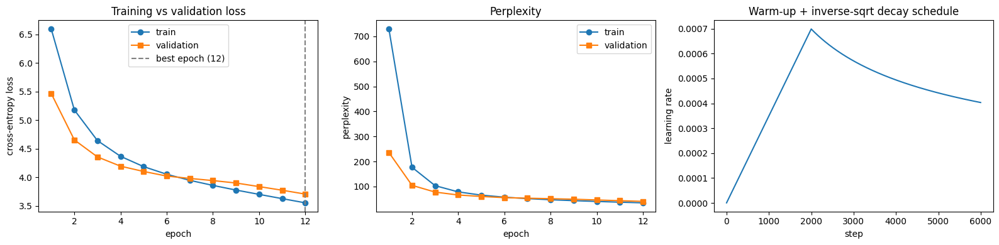

In [15]:
ep = range(1, len(history["train_loss"]) + 1)
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
ax[0].plot(ep, history["train_loss"], "o-", label="train"); ax[0].plot(ep, history["val_loss"], "s-", label="validation")
ax[0].axvline(BEST_EPOCH, ls="--", c="gray", label=f"best epoch ({BEST_EPOCH})")
ax[0].set(xlabel="epoch", ylabel="cross-entropy loss", title="Training vs validation loss"); ax[0].legend()
ax[1].plot(ep, np.exp(history["train_loss"]), "o-", label="train"); ax[1].plot(ep, np.exp(history["val_loss"]), "s-", label="validation")
ax[1].set(xlabel="epoch", ylabel="perplexity", title="Perplexity"); ax[1].legend()
steps = np.arange(1, 6000); ax[2].plot(steps, [noam(s - 1) for s in steps])
ax[2].set(xlabel="step", ylabel="learning rate", title="Warm-up + inverse-sqrt decay schedule")
plt.tight_layout(); plt.savefig("loss_curves.png", dpi=200); plt.show()

## 9. Generation (greedy, autoregressive, NO teacher forcing) and ROUGE on the full test set
* Start from `<start>`, feed each predicted token back in, stop at `<end>` or 128 tokens.
* The article is **encoded once**; the encoder output is reused at every step.
* Output ids are converted back to text; `[NL]` markers become `\n` so ROUGE-Lsum sees sentences.

In [16]:
@torch.no_grad()
def greedy_decode(model, src, max_len=MAX_TGT_LEN, return_attn=False):
    """Batched greedy decoding. Returns generated ids (B,<=max_len) [and last-layer cross-attn per step]."""
    model.eval()
    B = src.size(0)
    src_mask = make_src_mask(src)
    last_cross = model.dec_layers[-1].cross_attn
    last_cross.store_attn = return_attn
    with torch.autocast("cuda", dtype=torch.float16, enabled=USE_AMP):
        memory = model.encode(src, src_mask)                                   # encoder runs ONCE
        ys = torch.full((B, 1), START_ID, dtype=torch.long, device=src.device)
        finished = torch.zeros(B, dtype=torch.bool, device=src.device)
        attn_steps = []
        for _ in range(max_len):
            logits = model.decode(ys, memory, src_mask, make_tgt_mask(ys))[:, -1].float()   # (B,V)
            logits[:, PAD_ID] = -float("inf"); logits[:, START_ID] = -float("inf")
            nxt = logits.argmax(-1)                                            # greedy
            nxt = torch.where(finished, torch.full_like(nxt, PAD_ID), nxt)
            if return_attn:
                attn_steps.append(last_cross.attn[:, :, -1, :].float().cpu())  # (B,h,S) for the newest position
            ys = torch.cat([ys, nxt[:, None]], dim=1)
            finished |= nxt == END_ID
            if finished.all():
                break
    last_cross.store_attn = False
    return ys[:, 1:], (torch.stack(attn_steps, 1) if return_attn else None)    # attn: (B,T,h,S)

def ids_to_summary(ids):
    """ids -> text; sentences separated by '\n' (needed for ROUGE-Lsum)."""
    sents, cur = [], []
    for t in ids:
        if t == END_ID: break
        if t in (PAD_ID, START_ID): continue
        if t == NL_ID: sents.append(cur); cur = []
        else: cur.append(t)
    sents.append(cur)
    texts = [tok.decode(s, skip_special_tokens=True).strip() for s in sents if s]
    return "\n".join(t for t in texts if t)

def generate_all(model, src_list, batch_size=DECODE_BATCH):
    order = np.argsort([len(s) for s in src_list])                              # similar lengths together
    outs = [None] * len(src_list)
    for i in tqdm(range(0, len(order), batch_size), desc="generating"):
        idx = order[i:i + batch_size]
        src = pad_batch([src_list[j] for j in idx]).to(device)
        ys, _ = greedy_decode(model, src)
        for j, y in zip(idx, ys.tolist()):
            outs[j] = ids_to_summary(y)
    return outs

t0 = time.time()
test_preds = generate_all(model, test["src"])
print(f"Generated {len(test_preds)} summaries in {(time.time()-t0)/60:.1f} min")

generating:   0%|          | 0/180 [00:00<?, ?it/s]

Generated 11490 summaries in 15.0 min


In [18]:
ROUGE_KEYS = ["rouge1", "rouge2", "rougeL", "rougeLsum"]
scorer = rouge_scorer.RougeScorer(ROUGE_KEYS, use_stemmer=True)

def eval_rouge(preds, refs):
    agg = {k: [] for k in ROUGE_KEYS}
    for p, r in tqdm(list(zip(preds, refs)), desc="ROUGE"):
        s = scorer.score(r, p)                                   # score(target, prediction)
        for k in ROUGE_KEYS:
            agg[k].append(s[k].fmeasure)
    return {k: 100 * float(np.mean(v)) for k, v in agg.items()}   # F1 x 100, mean over the test set

model_scores = eval_rouge(test_preds, test["highlights"])

# Lead-3 baseline (no model) computed with the SAME scorer: verifies the evaluation pipeline.
# Expected on the full test set: R1 40.06 | R2 17.48 | RL 25.02 | RLsum 36.36
nltk.download("punkt", quiet=True); nltk.download("punkt_tab", quiet=True)
lead3_preds = ["\n".join(nltk.sent_tokenize(a)[:3]) for a in test["article"]]
lead3_scores = eval_rouge(lead3_preds, test["highlights"])

results = pd.DataFrame([model_scores, lead3_scores], index=["Transformer (ours, greedy)", "Lead-3 baseline"]).round(2)
results.columns = ["ROUGE-1", "ROUGE-2", "ROUGE-L", "ROUGE-Lsum"]
print(f"Test set size: {len(test_preds)}  |  ROUGE F1 (stemming on)")
display(results) if "display" in globals() else print(results)
json.dump({"ours": model_scores, "lead3": lead3_scores}, open("rouge_results.json", "w"), indent=2)
with open("test_generations.txt", "w") as f:
    for p, r in zip(test_preds, test["highlights"]):
        f.write(f"PRED:\n{p}\nREF:\n{r}\n{'-'*60}\n")

ROUGE:   0%|          | 0/11490 [00:00<?, ?it/s]

ROUGE:   0%|          | 0/11490 [00:00<?, ?it/s]

Test set size: 11490  |  ROUGE F1 (stemming on)
                            ROUGE-1  ROUGE-2  ROUGE-L  ROUGE-Lsum
Transformer (ours, greedy)    27.10     6.79    19.08       25.20
Lead-3 baseline               40.05    17.48    25.02       36.35


## 10. Qualitative analysis (>= 5 test articles + failure cases)

In [19]:
def trigram_repeat_rate(text):
    w = text.lower().split(); tri = list(zip(w, w[1:], w[2:]))
    return 0.0 if not tri else 1 - len(set(tri)) / len(tri)

def unsupported_numbers(summary, article):
    art_nums = set(re.findall(r"\d+", article))
    return sorted({n for n in re.findall(r"\d+", summary) if n not in art_nums})

def novel_words(summary, article):
    art = set(re.findall(r"[a-z']+", article.lower()))
    return sorted({w for w in re.findall(r"[a-z']+", summary.lower()) if w not in art})

def show(i, tag=""):
    p, r, a = test_preds[i], test["highlights"][i], test["article"][i]
    print("=" * 100); print(f"TEST #{i} {tag}")
    print("ARTICLE :", clean(a)[:450], "...")
    print("REFERENCE:", r.replace("\n", " | "))
    print("GENERATED:", p.replace("\n", " | "))
    print(f"  [repeat-trigram rate={trigram_repeat_rate(p):.2f} | numbers not in article={unsupported_numbers(p, a)} "
          f"| words not in article={novel_words(p, a)[:8]}]")

rng = random.Random(SEED)
random_ids = rng.sample(range(len(test_preds)), 5)
for i in random_ids: show(i, "(random example)")

# Automatically find failure cases for the report
rep  = sorted(range(len(test_preds)), key=lambda i: -trigram_repeat_rate(test_preds[i]))[:2]
nums = [i for i in range(len(test_preds)) if unsupported_numbers(test_preds[i], test["article"][i])][:2]
nov  = sorted(range(len(test_preds)), key=lambda i: -len(novel_words(test_preds[i], test["article"][i])))[:2]
for i in rep:  show(i, "(FAILURE: repeated phrases)")
for i in nums: show(i, "(FAILURE: number not in the article)")
for i in nov:  show(i, "(FAILURE: words/names not in the article)")

TEST #10476 (random example)
ARTICLE : President Barack Obama invited the Super Bowl champion New England Patriots to the White House on Thursday - but couldn't help but get one last deflategate joke in. The president opened his speech on the South Lawn by remarking 'that whole (deflategate) story got blown out of proportion,' referring to an investigation that 11 out of 12 footballs used in the AFC Championship game were under-inflated. But then came the zinger: 'I usually tell a bun ...
REFERENCE: Brady cited 'prior family commitments' in bowing out of meeting with Obama . | Has been to the White House to meet President George W. Bush for previous Super Bowl wins .
GENERATED: president obama invited the white house to the white house on thursday. | the president opened the remark as a joke that was inflated by the white house. | the president was also criticised by the patriots ' s team. | the president ' s team were also inflated by the white house.
  [repeat-trigram rate=0.08 | num

In [20]:
# Aggregate quality statistics (useful in the report)
gen_len = [len(p.split()) for p in test_preds]; ref_len = [len(r.split()) for r in test["highlights"]]
def novel_ngram_frac(preds, arts, n):
    num = den = 0
    for p, a in zip(preds, arts):
        pw, aw = p.lower().split(), a.lower().split()
        pg = list(zip(*[pw[i:] for i in range(n)])); ag = set(zip(*[aw[i:] for i in range(n)]))
        num += sum(g not in ag for g in pg); den += len(pg)
    return num / max(den, 1)
stats = {
    "avg generated length (words)": np.mean(gen_len), "avg reference length (words)": np.mean(ref_len),
    "outputs with repeated trigrams (>0.2 rate), %": 100 * np.mean([trigram_repeat_rate(p) > 0.2 for p in test_preds]),
    "outputs with a number absent from article, %": 100 * np.mean([bool(unsupported_numbers(p, a)) for p, a in zip(test_preds, test["article"])]),
    "novel unigrams vs article, %": 100 * novel_ngram_frac(test_preds, test["article"], 1),
    "novel bigrams vs article, %": 100 * novel_ngram_frac(test_preds, test["article"], 2),
}
print(pd.Series(stats).round(2).to_string())

avg generated length (words)                     54.88
avg reference length (words)                     55.01
outputs with repeated trigrams (>0.2 rate), %    56.33
outputs with a number absent from article, %      4.39
novel unigrams vs article, %                     19.53
novel bigrams vs article, %                      65.98


## 11. Encoder-decoder (cross) attention heatmap
Last decoder layer's cross-attention, **recorded while the model generates** (greedy, no teacher forcing),
**averaged over heads** in the main figure and **shown per head** in the second figure.
Rows = generated summary tokens, columns = a window of source tokens where most attention mass falls.

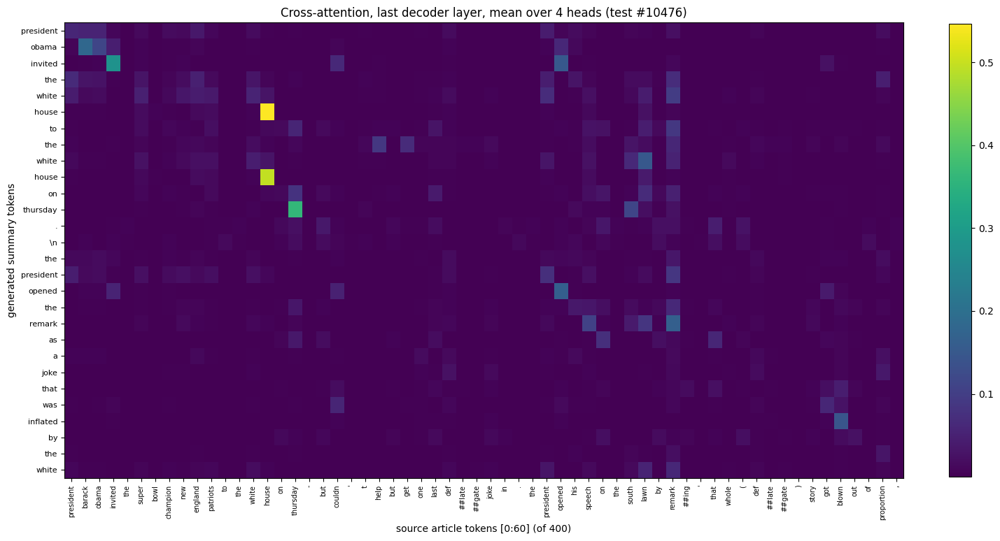

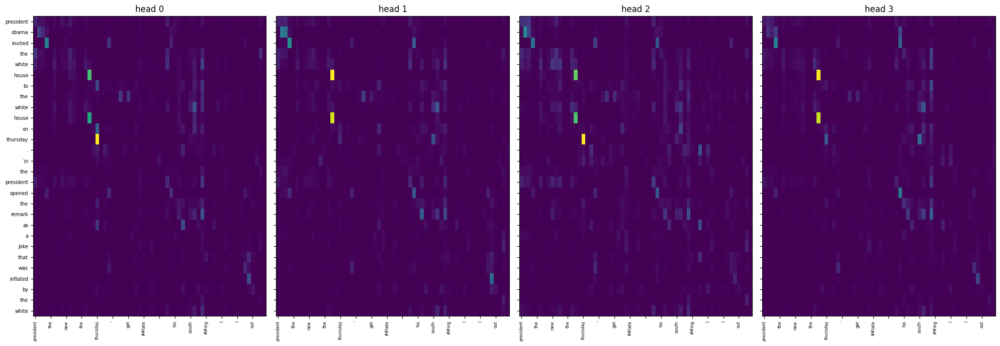

GENERATED: president obama invited the white house to the white house on thursday. | the president opened the remark as a joke that was inflated by the white
REFERENCE: Brady cited 'prior family commitments' in bowing out of meeting with Obama . | Has been to the White House to meet President George W. Bush for previous Super Bowl wins .


In [21]:
def token_labels(ids):
    labs = tok.convert_ids_to_tokens(ids)
    return ["\\n" if i == NL_ID else ("<end>" if i == END_ID else l) for i, l in zip(ids, labs)]

def attention_example(idx, window=60, max_rows=28, savepath="attention_heatmap.png"):
    src_ids = test["src"][idx]
    src = torch.tensor([src_ids], device=device)
    ys, attn = greedy_decode(model, src, return_attn=True)                      # attn: (1,T,h,S)
    gen = []
    for t in ys[0].tolist():
        gen.append(t)
        if t == END_ID: break
    A = attn[0, :len(gen)].numpy()                                              # (T,h,S)
    gen, A = gen[:max_rows], A[:max_rows]
    A_mean = A.mean(1)                                                          # average over heads -> (T,S)
    mass = A_mean.sum(0)                                                        # attention mass per source token
    w = min(window, len(src_ids))
    start = int(np.argmax(np.convolve(mass, np.ones(w), mode="valid")))         # window holding the most mass
    cols = slice(start, start + w)
    xl, yl = token_labels(src_ids[cols]), token_labels(gen)

    fig, ax = plt.subplots(figsize=(max(10, w * 0.24), max(5, len(gen) * 0.28)))
    im = ax.imshow(A_mean[:, cols], aspect="auto", cmap="viridis")
    ax.set_xticks(range(w)); ax.set_xticklabels(xl, rotation=90, fontsize=7)
    ax.set_yticks(range(len(gen))); ax.set_yticklabels(yl, fontsize=8)
    ax.set_xlabel(f"source article tokens [{start}:{start+w}] (of {len(src_ids)})"); ax.set_ylabel("generated summary tokens")
    ax.set_title(f"Cross-attention, last decoder layer, mean over {N_HEADS} heads (test #{idx})")
    plt.colorbar(im, ax=ax, fraction=0.025); plt.tight_layout(); plt.savefig(savepath, dpi=200); plt.show()

    fig, axes = plt.subplots(1, N_HEADS, figsize=(5 * N_HEADS, max(5, len(gen) * 0.25)), sharey=True)
    for h in range(N_HEADS):
        axes[h].imshow(A[:, h, cols], aspect="auto", cmap="viridis"); axes[h].set_title(f"head {h}")
        axes[h].set_xticks(range(0, w, 4)); axes[h].set_xticklabels(xl[::4], rotation=90, fontsize=6)
    axes[0].set_yticks(range(len(gen))); axes[0].set_yticklabels(yl, fontsize=7)
    plt.tight_layout(); plt.savefig(savepath.replace(".png", "_heads.png"), dpi=200); plt.show()
    print("GENERATED:", ids_to_summary(gen).replace("\n", " | "))
    print("REFERENCE:", test["highlights"][idx].replace("\n", " | "))

# pick the first random example with a reasonably long generated summary
viz_idx = next((i for i in random_ids if len(test_preds[i].split()) >= 15), random_ids[0])
attention_example(viz_idx)

## 12. Facts for the report (copy into the final report)

In [22]:
facts = {
    "Tokenizer": f"{TOKENIZER_NAME} WordPiece (pre-trained, uncased, shared vocab, {VOCAB_SIZE} tokens)",
    "Truncation": f"article {MAX_SRC_LEN} tokens, summary {MAX_TGT_LEN} tokens (incl. <start>/<end>)",
    "Model": f"{N_LAYERS} enc + {N_LAYERS} dec layers, d_model={D_MODEL}, heads={N_HEADS}, d_ff={D_FF}, dropout={DROPOUT}, tied emb={TIE_EMBEDDINGS}",
    "Parameters": f"{N_PARAMS:,}",
    "Training set size": f"{len(train['src']):,} pairs (random subset of 287,113 train; seed {SEED})",
    "Validation / test": f"{len(val['src']):,} val pairs (early stopping) / {len(test_preds):,} test pairs (final ROUGE only)",
    "Optimizer": f"Adam b=(0.9,0.98) eps=1e-9, Noam schedule warmup={WARMUP_STEPS}, factor={LR_FACTOR}, clip={CLIP_NORM}, batch={BATCH_SIZE}, AMP={USE_AMP}",
    "Early stopping": f"patience={PATIENCE} on val loss; best epoch={BEST_EPOCH}; best val loss={best_val:.4f}",
    "Decoding": f"greedy, max {MAX_TGT_LEN} tokens, encoder run once, no beam search",
    "ROUGE": "rouge_score, use_stemmer=True, F1 x100; ROUGE-L and ROUGE-Lsum reported separately",
}
for k, v in facts.items():
    print(f"{k:18s}: {v}")
print()
print(results.to_string())

Tokenizer         : bert-base-uncased WordPiece (pre-trained, uncased, shared vocab, 30522 tokens)
Truncation        : article 400 tokens, summary 128 tokens (incl. <start>/<end>)
Model             : 3 enc + 3 dec layers, d_model=256, heads=4, d_ff=1024, dropout=0.1, tied emb=True
Parameters        : 13,343,232
Training set size : 60,000 pairs (random subset of 287,113 train; seed 42)
Validation / test : 13,368 val pairs (early stopping) / 11,490 test pairs (final ROUGE only)
Optimizer         : Adam b=(0.9,0.98) eps=1e-9, Noam schedule warmup=2000, factor=0.5, clip=1.0, batch=32, AMP=False
Early stopping    : patience=3 on val loss; best epoch=12; best val loss=3.7040
Decoding          : greedy, max 128 tokens, encoder run once, no beam search
ROUGE             : rouge_score, use_stemmer=True, F1 x100; ROUGE-L and ROUGE-Lsum reported separately

                            ROUGE-1  ROUGE-2  ROUGE-L  ROUGE-Lsum
Transformer (ours, greedy)    27.10     6.79    19.08       25.20
Lead-3 ba